# OTT Streaming — Content Engagement Analytics (Hotstar)
### BITS Pilani Digital — Apex Project I · Final Submission Deliverable
* **Student Name:** Adarsh Mishra
* **BITS Student ID:** `2025eb1200013`
* **Cohort / Trimester:** Cohort 2, Trimester 3 (2025)
* **Problem Statement:** Problem Statement 5 — Digital Media and Streaming (Hotstar)
* **Central Defect:** Inconsistent labels and formats in playback event logs (`action`, `network_type`, bimodal `event_time`), duplicate event exports, missing content identifiers, and a content catalogue with unnormalized `genre`, `type`, and `age_rating` labels.

---

### Project Ground Rules & Scope Boundary
1. **Immutability of Raw Sources:** Never modify `events_raw` or `catalogue_raw`. Every transformation runs on an explicit copy.
2. **Auditability:** Every step states a **rule** and a **reason**, logging exact `rows_before`, `rows_after`, and `rows_changed`.
3. **Clean Before Join:** Standardize keys and recover unambiguous missing identifiers prior to joining. Report unmatched records transparently rather than dropping them silently.
4. **Scope Boundary:** No recommendation model training, no cloud deployment, and no front-end web dashboard. The deliverables are a verified, analysis-ready joined dataset (`clean_events.xlsx`), a side-by-side quality audit (`before_after_report.xlsx`), diagnostic visual charts, and an evidence-based answer to the closing research question.

## 0. Setup & Audit Cleaning Log
We set up the environment and create a `log()` helper function that appends every cleaning step, rule, rationale, and row count into a structured change-log.

In [1]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid")

cleaning_log = []

def log(step, rule, reason, before, after, notes=""):
    cleaning_log.append({
        "step": step,
        "rule": rule,
        "reason": reason,
        "rows_before": before,
        "rows_after": after,
        "rows_changed": before - after,
        "notes": notes
    })

print("Setup complete. Audit cleaning log initialized.")

Setup complete. Audit cleaning log initialized.


## 1. Source Ingestion & Baseline Snapshot (Steps 1 & 2)
We load both datasets directly from their Excel (.xlsx) exports:
1. `hotstar_raw_synthetic_event_log.xlsx` — Synthetic playback telemetry (13,243 rows × 11 columns)
2. `hotstar_catalogue_raw_style.xlsx` — Content catalogue master table (6,874 rows × 10 columns)

Before applying any cleaning rules, we record a **BEFORE** snapshot of our core data-quality metrics so we can prove every improvement quantitatively.

In [2]:
from pathlib import Path
import importlib
import subprocess
import sys
import zipfile

# Ensure Excel reader/writer engines ('openpyxl' for .xlsx, 'xlrd' for .xls) are available
for _pkg in ("openpyxl", "xlrd"):
    try:
        importlib.import_module(_pkg)
    except ImportError:
        try:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", _pkg])
        except Exception:
            pass

def resolve_or_extract_excel(primary_xlsx, fallback_xls):
    search_dirs = [
        Path.cwd(),
        Path.cwd() / "Data Sets",
        Path.cwd() / "datasets",
        Path.cwd().parent,
        Path.cwd().parent / "Data Sets",
        Path.home() / "Downloads",
        Path.home() / "Downloads" / "Data Sets",
    ]

    # 1. Prioritize .xlsx across all standard locations first (uses openpyxl, no xlrd needed)
    for d in search_dirs:
        if d.exists():
            direct = d / primary_xlsx
            if direct.exists():
                return direct

    # 2. Recursive search for .xlsx inside current working directory
    for match in Path.cwd().rglob(primary_xlsx):
        if match.is_file():
            return match

    # 3. Check ZIP archives in working directory or Downloads and auto-extract Data Sets/
    for d in search_dirs:
        if d.exists():
            for zpath in sorted(d.glob("*.zip"), key=lambda p: p.stat().st_mtime, reverse=True):
                try:
                    with zipfile.ZipFile(zpath, "r") as zf:
                        names = zf.namelist()
                        target_in_zip = next((n for n in names if n.endswith(primary_xlsx)), None)
                        if target_in_zip:
                            zf.extractall(Path.cwd())
                            for candidate in [Path.cwd() / target_in_zip, Path.cwd() / "Data Sets" / primary_xlsx, Path.cwd() / primary_xlsx]:
                                if candidate.exists():
                                    print(f"Automatically extracted '{primary_xlsx}' from '{zpath.name}'")
                                    return candidate
                except Exception:
                    continue

    # 4. Fallback to legacy .xls files if no .xlsx was found anywhere
    for d in search_dirs:
        if d.exists():
            direct_xls = d / fallback_xls
            if direct_xls.exists():
                return direct_xls

    raise FileNotFoundError(
        f"Could not find '{primary_xlsx}' or '{fallback_xls}'. "
        f"Please extract the full submission ZIP folder first and place '{primary_xlsx}' in {Path.cwd() / 'Data Sets'}"
    )

def load_excel_file(filepath):
    ext = Path(filepath).suffix.lower()
    if ext == ".xlsx":
        return pd.read_excel(filepath, engine="openpyxl")
    elif ext == ".xls":
        try:
            return pd.read_excel(filepath, engine="xlrd")
        except ImportError as exc:
            raise ImportError(
                "Legacy .xls file detected, but 'xlrd' is not installed. "
                "Either extract the full ZIP folder (which includes .xlsx files in 'Data Sets/') "
                "or run: pip install xlrd"
            ) from exc
    return pd.read_excel(filepath)

events_path = resolve_or_extract_excel(
    "hotstar_raw_synthetic_event_log.xlsx",
    "hotstar_raw_synthetic_event_log.xls"
)
catalogue_path = resolve_or_extract_excel(
    "hotstar_catalogue_raw_style.xlsx",
    "hotstar_catalogue_raw_style.xls"
)

events_raw = load_excel_file(events_path)
catalogue_raw = load_excel_file(catalogue_path)

# Keep raw copies untouched; work strictly on copies
df_events = events_raw.copy()
df_cat = catalogue_raw.copy()

print(f"Playback Event Log shape : {events_raw.shape[0]:,} rows x {events_raw.shape[1]} columns")
print(f"Content Catalogue shape  : {catalogue_raw.shape[0]:,} rows x {catalogue_raw.shape[1]} columns")

before_snapshot = {
    "event_rows": len(events_raw),
    "exact_duplicate_events": int(events_raw.duplicated().sum()),
    "distinct_action_labels": int(events_raw["action"].nunique()),
    "distinct_network_labels": int(events_raw["network_type"].nunique()),
    "missing_content_id": int(events_raw["content_id"].isna().sum()),
    "missing_content_name": int(events_raw["content_name"].isna().sum()),
    "missing_profile_id": int(events_raw["profile_id"].isna().sum()),
    "missing_client_device": int(events_raw["client_device"].isna().sum()),
    "missing_network_type": int(events_raw["network_type"].isna().sum()),
    "catalogue_rows": len(catalogue_raw),
    "distinct_genre_labels": int(catalogue_raw["genre"].nunique()),
    "distinct_type_labels": int(catalogue_raw["type"].nunique()),
    "distinct_rating_labels": int(catalogue_raw["age_rating"].nunique()),
    "missing_catalogue_genre": int(catalogue_raw["genre"].isna().sum()),
    "missing_catalogue_rating": int(catalogue_raw["age_rating"].isna().sum()),
}

pd.Series(before_snapshot, name="BEFORE_CLEANING")

Playback Event Log shape : 13,243 rows x 11 columns
Content Catalogue shape  : 6,874 rows x 10 columns


event_rows                  13243
exact_duplicate_events        105
distinct_action_labels         24
distinct_network_labels         5
missing_content_id            173
missing_content_name          325
missing_profile_id            153
missing_client_device         228
missing_network_type          359
catalogue_rows               6874
distinct_genre_labels          92
distinct_type_labels           10
distinct_rating_labels         21
missing_catalogue_genre        41
missing_catalogue_rating       54
Name: BEFORE_CLEANING, dtype: int64

In [3]:
try:
    display(df_events.head(3))
    display(df_cat.head(3))
except NameError:
    print(df_events.head(3))
    print(df_cat.head(3))

print("--- Event Log Profiling Summary ---")
print(pd.DataFrame({"dtype": df_events.dtypes, "nulls": df_events.isna().sum(), "nunique": df_events.nunique()}))

print("\n--- Content Catalogue Profiling Summary ---")
print(pd.DataFrame({"dtype": df_cat.dtypes, "nulls": df_cat.isna().sum(), "nunique": df_cat.nunique()}))

,event_key,profile_id,content_id,content_name,action,event_time,client_device,app_version,network_type,playhead_seconds,country_code
0,evt-0012390,user_0501,1.260123e+09,Iravatham,play,2025-08-06 08:22:10,Smart TV,4.1.0,Wi-Fi,6.0,IN
1,evt-0000386,user_0468,4.112000e+03,Seethamaalakshmi,play,2025-07-25 09:56:16,Tablet,4.0.2,mobile_data,44.0,IN
2,evt-0004897,user_0216,1.707800e+04,Jalsha-e Anupam,stop,2025-01-23 21:40:02,Smart TV,4.2.0,mobile_data,2155.8,IN


,hotstar_id,title,description,genre,year,age_rating,running_time,seasons,episodes,type
0,1000087439,Sambha - Aajcha Chawa,A young man sets off on a mission to clean up the society from corruption and other ev...,Action,2012,U/A 16+,141.0,NaN,NaN,movie
1,1260023113,Cars Toon: Mater And The Ghostlight,Mater is haunted by a mysterious blue light that teaches him not to play pranks on the...,Animation,2006,U,7.0,NaN,NaN,movie
2,1260103188,Kanmani Rambo Khatija,"Unlucky since birth, Rambo finds hope when he falls in love with Kanmani and Khatija. ...",Romance,2022,U/A 16+,157.0,NaN,NaN,movie


--- Event Log Profiling Summary ---
                    dtype  nulls  nunique
event_key             str      0    13138
profile_id            str    153      520
content_id        float64    173     2529
content_name       object    325     2499
action                str      0       24
event_time            str      0    13000
client_device         str    228        5
app_version           str      0        6
network_type          str    359        5
playhead_seconds  float64      0     3756
country_code          str      0        3

--- Content Catalogue Profiling Summary ---
                dtype  nulls  nunique
hotstar_id      int64      0     6874
title          object      0     6677
description       str    123     6695
genre             str     41       92
year            int64      0       78
age_rating        str     54       21
running_time  float64   2306      187
seasons       float64   4568       40
episodes      float64   4568      495
type              str      0       

## 2. Deduplication of Repeat Exports (Step 3)
Profiling showed `events_raw.duplicated().sum() == 105` fully identical rows, where `event_key` is also repeated 105 times. Because these represent overlapping batch exports rather than distinct user playback events, we drop exact duplicates keeping the first occurrence (`13,243 → 13,138`).

In [4]:
n0 = len(df_events)
exact_dups = df_events.duplicated().sum()
key_dups = df_events["event_key"].duplicated().sum()
print(f"Exact duplicate rows: {exact_dups} | Repeated event_keys: {key_dups}")

df_events = df_events.drop_duplicates(keep="first").copy()

log(
    step="Step 3: Exact Deduplication",
    rule="Drop rows identical across all 11 columns (keep='first')",
    reason="Overlapping export batches re-extracted identical event records",
    before=n0,
    after=len(df_events),
    notes=f"Unique event_keys retained: {df_events['event_key'].nunique():,}"
)
print(f"Rows after deduplication: {n0:,} -> {len(df_events):,}")

Exact duplicate rows: 105 | Repeated event_keys: 105
Rows after deduplication: 13,243 -> 13,138


## 3. Categorical & String Standardization (Step 4)
Both sources suffer from inconsistent casing and leading/trailing whitespace:
* **Event Log:**
  * `action` contains **24 distinct strings** (`'play'`, `'PLAY'`, `' play'`, etc.) representing **8 canonical player actions**.
  * `network_type` splits wireless sessions across `'wifi'` and `'Wi-Fi'` (5 raw labels → 4 canonical categories).
  * `client_device` is stripped of accidental padding whitespace.
* **Content Catalogue:**
  * `genre` has **92 raw strings** collapsing to **37 canonical genres** (plus `'unknown'` for 41 blanks).
  * `type` has **10 spellings** (`'movie'`, `'Movie'`, `'MOVIE'`, `' movie'`, etc.) collapsing to **2 binary types** (`'movie'`, `'tv'`).
  * `age_rating` has **21 spellings** collapsing to **6 standard certifications** (`'U'`, `'U/A 7+'`, `'U/A 13+'`, `'U/A 16+'`, `'A'`, `'PG'`).

In [5]:
# Clean Event Log categorical strings
df_events["action_clean"] = df_events["action"].astype(str).str.strip().str.lower()
df_events["network_clean"] = (
    df_events["network_type"]
    .str.strip()
    .str.lower()
    .replace({"wi-fi": "wifi"})
)
df_events["device_clean"] = df_events["client_device"].str.strip()

# Clean Content Catalogue categorical strings
df_cat["genre_clean"] = df_cat["genre"].str.strip().str.lower()
df_cat["type_clean"] = df_cat["type"].str.strip().str.lower()
df_cat["age_rating_clean"] = df_cat["age_rating"].str.strip().str.upper()

print("Event Log Label Consolidation:")
print(f"  action      : {events_raw['action'].nunique()} -> {df_events['action_clean'].nunique()}")
print(f"  network_type: {events_raw['network_type'].nunique()} -> {df_events['network_clean'].nunique()}")

print("\nCatalogue Label Consolidation:")
print(f"  genre       : {catalogue_raw['genre'].nunique()} -> {df_cat['genre_clean'].nunique()}")
print(f"  type        : {catalogue_raw['type'].nunique()} -> {df_cat['type_clean'].nunique()}")
print(f"  age_rating  : {catalogue_raw['age_rating'].nunique()} -> {df_cat['age_rating_clean'].nunique()}")

log(
    step="Step 4: String Standardization",
    rule="Strip whitespace & normalize case; map 'Wi-Fi' -> 'wifi'",
    reason="Eliminate category fragmentation from raw casing and whitespace variants",
    before=len(df_events),
    after=len(df_events),
    notes="Actions: 24->8, Networks: 5->4 canonical (5 incl. 'unknown' post-imputation), Genres: 92->37, Types: 10->2, Ratings: 21->6"
)


Event Log Label Consolidation:
  action      : 24 -> 8
  network_type: 5 -> 4

Catalogue Label Consolidation:
  genre       : 92 -> 37
  type        : 10 -> 2
  age_rating  : 21 -> 6


## 4. Bimodal Timestamp Parsing & Near-Duplicate Check (Step 5)
In profiling, `event_time` appeared in two text formats:
1. **ISO dash format (`YYYY-MM-DD HH:MM:SS`)**: 9,797 raw rows.
2. **Day-first slash format (`DD/MM/YYYY HH:MM`)**: 3,446 raw rows (in 2,129 rows the first token exceeds 12 while the second never does, confirming day-first ordering).

We parse each format separately with `errors="coerce"`, verify zero `NaT` failures, and assert that all timestamps fall within **2025**. We also inspect the 1 composite near-duplicate candidate identified in risk analysis (`evt-0011954` vs `evt-0011955`).

In [6]:
n0 = len(df_events)
iso_mask = df_events["event_time"].str.contains("-", na=False)

dt_iso = pd.to_datetime(df_events.loc[iso_mask, "event_time"], format="%Y-%m-%d %H:%M:%S", errors="coerce")
dt_slash = pd.to_datetime(df_events.loc[~iso_mask, "event_time"], format="%d/%m/%Y %H:%M", errors="coerce")

df_events["event_dt"] = pd.concat([dt_iso, dt_slash]).sort_index()

unparsed_count = df_events["event_dt"].isna().sum()
assert unparsed_count == 0, f"Found {unparsed_count} unparseable timestamps!"
assert (df_events["event_dt"].dt.year == 2025).all(), "Found timestamps outside 2025!"

print(f"Unparseable timestamps : {unparsed_count}")
print(f"Parsed datetime range  : {df_events['event_dt'].min()}  to  {df_events['event_dt'].max()}")

# Check composite duplicates ignoring event_key
comp_cols = ["profile_id", "content_id", "action_clean", "event_dt", "playhead_seconds"]
comp_dups = df_events[df_events.duplicated(subset=comp_cols, keep=False)]
print(f"\nComposite near-duplicate candidates (differing in event_key/network/app_version): {len(comp_dups)} rows")
display(comp_dups[["event_key", "profile_id", "content_name", "action_clean", "event_dt", "network_clean", "app_version", "playhead_seconds"]])

# Judgement call: Retain both rows because network_type ('wifi' vs '5g') and app_version differ,
# indicating a legitimate mid-stream network handover retry rather than an export error.
log(
    step="Step 5: Timestamp Parsing",
    rule="Parse ISO (%Y-%m-%d %H:%M:%S) and Slash (%d/%m/%Y %H:%M) separately into datetime64",
    reason="Resolve bimodal date strings without month/day inversion",
    before=n0,
    after=len(df_events),
    notes="0 NaT values; all 13,138 events verified within 2025"
)

Unparseable timestamps : 0
Parsed datetime range  : 2025-01-01 06:28:00  to  2025-12-31 22:59:50

Composite near-duplicate candidates (differing in event_key/network/app_version): 2 rows


,event_key,profile_id,content_name,action_clean,event_dt,network_clean,app_version,playhead_seconds
7883,evt-0011954,user_0447,Firefly,pause,2025-11-18 19:01:00,wifi,3.8.1,780.0
12051,evt-0011955,user_0447,Firefly,pause,2025-11-18 19:01:00,5g,4.1.0,780.0


## 5. Join Key Alignment, Title-to-ID Recovery & Left Join (Steps 6 & 7)
1. **Nullable Integer Typing:** Because `content_id` has 173 missing values, Pandas loads it as `float64`. We cast it to nullable `Int64`.
2. **Unambiguous Recovery:** Out of 167 deduplicated events missing `content_id` where `content_name` is present:
   * **161 rows** match a catalogue title that exists under **only one** `hotstar_id` (`unambiguous`). We recover their exact `hotstar_id`.
   * **6 rows** match titles that exist under multiple `hotstar_id`s (`ambiguous` remakes/re-uploads) and **6 rows** have neither `content_id` nor `content_name`. We route these **12 rows** into explicit `'unlinked'` audit flags rather than guessing.
3. **Left Join:** We left-join `df_events` to `df_cat` on `content_id_clean == hotstar_id` and assert that the row count stays strictly `13,138`.

In [7]:
n0 = len(df_events)

df_events["content_id_clean"] = df_events["content_id"].astype("Int64")

# Build lookup dictionary strictly from titles appearing once in the catalogue
title_freq = df_cat["title"].value_counts()
unambiguous_titles = set(title_freq[title_freq == 1].index)
title_to_id_map = (
    df_cat[df_cat["title"].isin(unambiguous_titles)]
    .set_index("title")["hotstar_id"]
    .to_dict()
)

name_only_mask = df_events["content_id_clean"].isna() & df_events["content_name"].notna()
mapped_ids = df_events.loc[name_only_mask, "content_name"].map(title_to_id_map)

recovered_mask = name_only_mask & mapped_ids.notna()
df_events.loc[recovered_mask, "content_id_clean"] = mapped_ids.dropna().astype("Int64")

# Track link reconciliation status
df_events["link_status"] = "matched_direct"
df_events.loc[recovered_mask, "link_status"] = "recovered_by_title"
df_events.loc[df_events["content_id_clean"].isna() & df_events["content_name"].notna(), "link_status"] = "unlinked_ambiguous_title"
df_events.loc[df_events["content_id_clean"].isna() & df_events["content_name"].isna(), "link_status"] = "unlinked_missing_both"

print("Content ID Reconciliation Breakdown:")
print(df_events["link_status"].value_counts())

log(
    step="Step 6: Join Key Recovery",
    rule="Cast content_id to Int64; recover 161 unambiguous name-only rows; flag 12 unlinked rows",
    reason="Recover valid foreign keys without risking false matches on duplicate titles",
    before=n0,
    after=len(df_events),
    notes="161 IDs recovered; 6 ambiguous and 6 double-null rows flagged"
)

# Step 7: Left Join on content_id_clean = hotstar_id
cat_cols_to_join = [
    "hotstar_id", "title", "genre_clean", "year",
    "age_rating_clean", "running_time", "seasons", "episodes", "type_clean"
]
df_joined = df_events.merge(
    df_cat[cat_cols_to_join],
    left_on="content_id_clean",
    right_on="hotstar_id",
    how="left"
)

assert len(df_joined) == n0, "Row count changed after left join!"
unmatched_after_join = df_joined["hotstar_id"].isna().sum()
print(f"\nRows after left join: {len(df_joined):,} | Unmatched rows: {unmatched_after_join}")

log(
    step="Step 7: Catalogue Left Join",
    rule="Left join events -> catalogue on content_id_clean = hotstar_id",
    reason="Enrich player telemetry with content metadata while preserving all 13,138 valid events",
    before=n0,
    after=len(df_joined),
    notes=f"Join coverage rose 98.68% (12,965/13,138) -> 99.91% (13,126/13,138); {unmatched_after_join} explicitly flagged unlinked"
)


Content ID Reconciliation Breakdown:
link_status
matched_direct              12965
recovered_by_title            161
unlinked_missing_both           6
unlinked_ambiguous_title        6
Name: count, dtype: int64

Rows after left join: 13,138 | Unmatched rows: 12


## 6. Missing Value Handling & Domain Validation (Steps 8 & 9)
* **Explicit `'unknown'` Categories (Step 8):** Missing values in `profile_id` (151 deduplicated rows; 153 raw), `client_device` (225 deduplicated rows; 228 raw), `network_type` (356 deduplicated rows; 359 raw), and missing catalogue attributes (`genre_clean`, `age_rating_clean`, `type_clean`) are preserved under explicit `'unknown'` labels so we do not lose aggregate play volume.
* **Structural Null Preservation:** `running_time` is blank for TV series and `seasons`/`episodes` are blank for movies. These structural blanks are left intact.
* **Domain Value Validation (Step 9):**
  * Verify `playhead_seconds >= 0` across all events.
  * Verify `playhead_seconds <= running_time * 60` for movies.
  * Flag short-format movies (`running_time <= 5` minutes; 137 titles in the catalogue) via `is_short_film` rather than deleting them.

In [8]:
n0 = len(df_joined)

# Step 8: Impute operational categoricals with 'unknown'
df_joined["profile_id_clean"] = df_joined["profile_id"].fillna("unknown")
df_joined["device_clean"] = df_joined["device_clean"].fillna("unknown")
df_joined["network_clean"] = df_joined["network_clean"].fillna("unknown")
df_joined["genre_clean"] = df_joined["genre_clean"].fillna("unknown")
df_joined["age_rating_clean"] = df_joined["age_rating_clean"].fillna("UNKNOWN")
df_joined["type_clean"] = df_joined["type_clean"].fillna("unknown")
df_joined["title_clean"] = df_joined["title"].fillna(df_joined["content_name"]).fillna("Unknown Title")

log(
    step="Step 8: Missing Value Handling",
    rule="Impute missing categoricals (profile_id, device, network, genre, rating) as 'unknown'",
    reason="Retain 100% of playback volume while keeping structural TV/movie nulls intact",
    before=n0,
    after=len(df_joined),
    notes="Structural nulls in running_time (TV) and seasons/episodes (movies) preserved"
)

# Step 9: Domain Value Validation
neg_playhead = (df_joined["playhead_seconds"] < 0).sum()
movie_rows = df_joined["type_clean"] == "movie"
exceeds_runtime = (movie_rows & (df_joined["playhead_seconds"] > df_joined["running_time"] * 60)).sum()

df_joined["is_short_film"] = (df_joined["type_clean"] == "movie") & (df_joined["running_time"] <= 5)

print(f"Negative playhead_seconds count          : {neg_playhead}")
print(f"Movie playhead exceeding runtime count   : {exceeds_runtime}")
print(f"Events on short films (<= 5 min runtime) : {df_joined['is_short_film'].sum()}")

log(
    step="Step 9: Domain Validation",
    rule="Assert playhead_seconds >= 0 & <= movie runtime; flag short films (<= 5 min)",
    reason="Validate playback bounds and isolate short-format titles without dropping valid rows",
    before=n0,
    after=len(df_joined),
    notes=f"0 invalid playhead bounds; {df_joined['is_short_film'].sum()} short-film events flagged"
)

Negative playhead_seconds count          : 0
Movie playhead exceeding runtime count   : 0
Events on short films (<= 5 min runtime) : 306


## 7. Feature Engineering & Completion Logic (Step 10)
We engineer temporal attributes (`hour`, `day_of_week`, `month`, `is_peak_hour` for evening prime time `18:00–23:59`) and implement the explicit dual-condition completion indicator:
$$\text{is\_completed\_event} = 1 \quad \text{if } \texttt{action\_clean} == \text{'complete'} \;\lor\; \big(\texttt{running\_time} > 0 \;\land\; \texttt{playhead\_seconds} \ge 0.90 \times \texttt{running\_time} \times 60\big)$$

> **Methodological Note on Completion Definitions:** The dual-rule indicator `is_completed_event` flags **972 events** (`440` explicit `'complete'` packets plus `532` non-complete packets—such as `stop` or `pause`—where `playhead_seconds` reached $\ge 90\%$ of runtime, including `178` events on short films $\le 5$ min). To prevent short-title pauses from inflating completion rates, the operational **Complete-to-Play Ratios** in Section 10 strictly use explicit `action_clean == 'complete'` (`440` completes / `3,200` plays).

In [9]:
n0 = len(df_joined)

df_joined["hour"] = df_joined["event_dt"].dt.hour
df_joined["day_of_week"] = df_joined["event_dt"].dt.day_name()
df_joined["month"] = df_joined["event_dt"].dt.month
df_joined["is_peak_hour"] = df_joined["hour"].between(18, 23)

reached_90pct = (
    (df_joined["running_time"].notna()) &
    (df_joined["running_time"] > 0) &
    (df_joined["playhead_seconds"] >= 0.90 * df_joined["running_time"] * 60)
)
df_joined["is_completed_event"] = ((df_joined["action_clean"] == "complete") | reached_90pct).astype(int)

eng_cols = ["hour", "day_of_week", "month", "is_peak_hour", "is_completed_event"]
assert df_joined[eng_cols].isna().sum().sum() == 0, "Unexpected nulls in engineered features!"

print(f"Explicit 'complete' events : {(df_joined['action_clean'] == 'complete').sum():,}")
print(f"Dual-rule completed events : {df_joined['is_completed_event'].sum():,}")
print(f"Peak-hour events (18-23h)  : {df_joined['is_peak_hour'].sum():,} ({df_joined['is_peak_hour'].mean():.1%})")

log(
    step="Step 10: Feature Engineering",
    rule="Extract hour, day_of_week, month, is_peak_hour (18-23h); add dual is_completed_event flag",
    reason="Support temporal engagement breakdown and standardized completion tracking",
    before=n0,
    after=len(df_joined),
    notes="0 nulls across all 5 engineered columns"
)

Explicit 'complete' events : 440
Dual-rule completed events : 972
Peak-hour events (18-23h)  : 5,861 (44.6%)


## 8. Before vs. After Data Quality Audit Report (Step 11)
We place the **BEFORE** snapshot next to the **AFTER** snapshot across identical metrics to demonstrate the exact impact of our cleaning pipeline.

In [10]:
after_snapshot = {
    "event_rows": len(df_joined),
    "exact_duplicate_events": int(df_joined.duplicated().sum()),
    "distinct_action_labels": int(df_joined["action_clean"].nunique()),
    "distinct_network_labels": int(df_joined["network_clean"].nunique()),
    "missing_content_id": int(df_joined["content_id_clean"].isna().sum()),
    "missing_content_name": int((df_joined["title_clean"] == "Unknown Title").sum()),
    "missing_profile_id": int((df_joined["profile_id_clean"] == "unknown").sum()),
    "missing_client_device": int((df_joined["device_clean"] == "unknown").sum()),
    "missing_network_type": int((df_joined["network_clean"] == "unknown").sum()),
    "catalogue_rows": len(df_cat),
    "distinct_genre_labels": int(df_cat["genre_clean"].dropna().nunique()),
    "distinct_type_labels": int(df_cat["type_clean"].dropna().nunique()),
    "distinct_rating_labels": int(df_cat["age_rating_clean"].dropna().nunique()),
    "missing_catalogue_genre": int(df_cat["genre_clean"].isna().sum()),
    "missing_catalogue_rating": int(df_cat["age_rating_clean"].isna().sum()),
}

quality_report_df = pd.DataFrame({
    "Metric": [k if k != "distinct_network_labels" else "distinct_network_labels (4 canonical + 'unknown')" for k in before_snapshot.keys()],
    "Before_Cleaning": list(before_snapshot.values()),
    "After_Cleaning": list(after_snapshot.values())
})
quality_report_df["Net_Change"] = quality_report_df["After_Cleaning"] - quality_report_df["Before_Cleaning"]

display(quality_report_df)

print("\n--- Full Pipeline Execution & Cleaning Log ---")
cleaning_log_df = pd.DataFrame(cleaning_log)
display(cleaning_log_df[["step", "rule", "rows_before", "rows_after", "rows_changed", "notes"]])


,Metric,Before_Cleaning,After_Cleaning,Net_Change
0,event_rows,13243,13138,-105
1,exact_duplicate_events,105,0,-105
2,distinct_action_labels,24,8,-16
3,distinct_network_labels (4 canonical + 'unknown'),5,5,0
4,missing_content_id,173,12,-161
5,missing_content_name,325,6,-319
6,missing_profile_id,153,151,-2
7,missing_client_device,228,225,-3
8,missing_network_type,359,356,-3
9,catalogue_rows,6874,6874,0



--- Full Pipeline Execution & Cleaning Log ---


,step,rule,rows_before,rows_after,rows_changed,notes
0,Step 3: Exact Deduplication,Drop rows identical across all 11 columns (keep='first'),13243,13138,105,"Unique event_keys retained: 13,138"
1,Step 4: String Standardization,Strip whitespace & normalize case; map 'Wi-Fi' -> 'wifi',13138,13138,0,"Actions: 24->8, Networks: 5->4 canonical (5 incl. 'unknown' post-imputation), Genres: ..."
2,Step 5: Timestamp Parsing,Parse ISO (%Y-%m-%d %H:%M:%S) and Slash (%d/%m/%Y %H:%M) separately into datetime64,13138,13138,0,"0 NaT values; all 13,138 events verified within 2025"
3,Step 6: Join Key Recovery,Cast content_id to Int64; recover 161 unambiguous name-only rows; flag 12 unlinked rows,13138,13138,0,161 IDs recovered; 6 ambiguous and 6 double-null rows flagged
4,Step 7: Catalogue Left Join,Left join events -> catalogue on content_id_clean = hotstar_id,13138,13138,0,"Join coverage rose 98.68% (12,965/13,138) -> 99.91% (13,126/13,138); 12 explicitly fla..."
5,Step 8: Missing Value Handling,"Impute missing categoricals (profile_id, device, network, genre, rating) as 'unknown'",13138,13138,0,Structural nulls in running_time (TV) and seasons/episodes (movies) preserved
6,Step 9: Domain Validation,Assert playhead_seconds >= 0 & <= movie runtime; flag short films (<= 5 min),13138,13138,0,0 invalid playhead bounds; 306 short-film events flagged
7,Step 10: Feature Engineering,"Extract hour, day_of_week, month, is_peak_hour (18-23h); add dual is_completed_event flag",13138,13138,0,0 nulls across all 5 engineered columns


## 9. Exploratory Data Analysis & Required Charts
We generate both required visual deliverables:
* **Chart 1:** Categorical Label Consolidation (`genre`, `action`, `age_rating`, `type`, `network_type` — Before vs. After Cleaning).
* **Chart 2:** Viewing Activity by Hour of Day Split by Client Device Platform (`Android`, `Smart TV`, `Web`, `iOS`, `Tablet`).

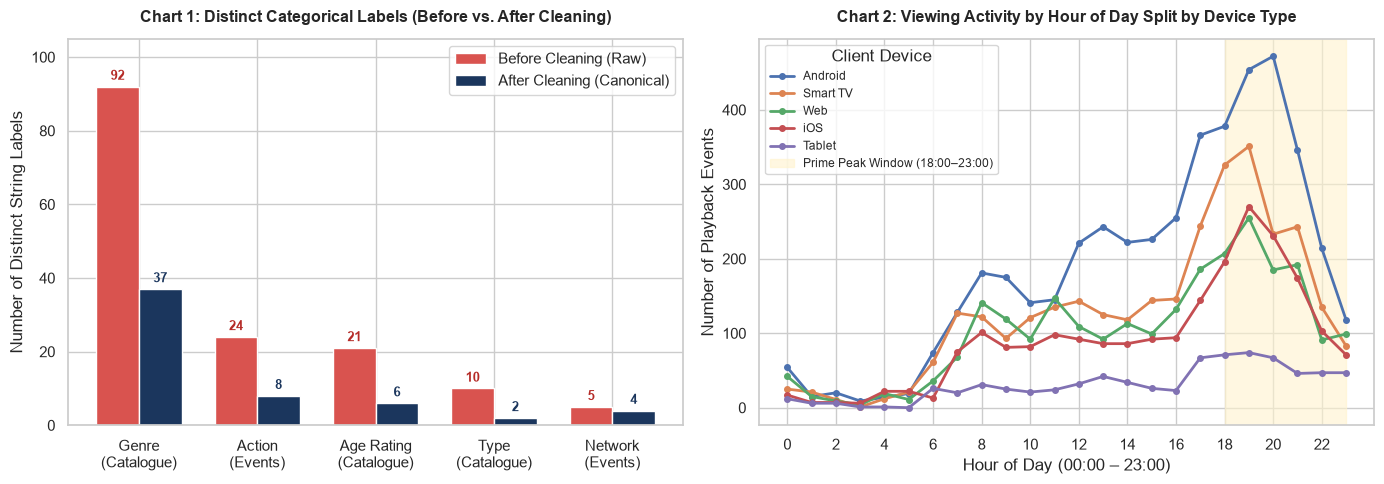

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- CHART 1: Taxonomy Cardinality Reduction (Before vs After) ---
categories = ["Genre\n(Catalogue)", "Action\n(Events)", "Age Rating\n(Catalogue)", "Type\n(Catalogue)", "Network\n(Events)"]
raw_counts = [
    before_snapshot["distinct_genre_labels"],
    before_snapshot["distinct_action_labels"],
    before_snapshot["distinct_rating_labels"],
    before_snapshot["distinct_type_labels"],
    before_snapshot["distinct_network_labels"]
]
clean_counts = [
    after_snapshot["distinct_genre_labels"],
    after_snapshot["distinct_action_labels"],
    after_snapshot["distinct_rating_labels"],
    after_snapshot["distinct_type_labels"],
    df_joined[df_joined["network_clean"] != "unknown"]["network_clean"].nunique()
]

x = np.arange(len(categories))
width = 0.36

rects1 = axes[0].bar(x - width/2, raw_counts, width, label="Before Cleaning (Raw)", color="#d9534f")
rects2 = axes[0].bar(x + width/2, clean_counts, width, label="After Cleaning (Canonical)", color="#1b365d")

axes[0].set_title("Chart 1: Distinct Categorical Labels (Before vs. After Cleaning)", fontsize=11.5, fontweight="bold", pad=12)
axes[0].set_ylabel("Number of Distinct String Labels")
axes[0].set_xticks(x)
axes[0].set_xticklabels(categories)
axes[0].legend()
axes[0].set_ylim(0, 105)

for rect in rects1:
    h = rect.get_height()
    axes[0].annotate(f"{h}", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                     textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#b52b27")
for rect in rects2:
    h = rect.get_height()
    axes[0].annotate(f"{h}", xy=(rect.get_x() + rect.get_width()/2, h), xytext=(0, 3),
                     textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold", color="#1b365d")

# --- CHART 2: Hourly Viewing Activity by Client Device ---
known_devices = ["Android", "Smart TV", "Web", "iOS", "Tablet"]
hourly_device = (
    df_joined[df_joined["device_clean"].isin(known_devices)]
    .groupby(["hour", "device_clean"])
    .size()
    .unstack(fill_value=0)[known_devices]
)

hourly_device.plot(ax=axes[1], marker="o", linewidth=2, markersize=4)
axes[1].axvspan(18, 23, color="#fff3cd", alpha=0.6, label="Prime Peak Window (18:00–23:00)")
axes[1].set_title("Chart 2: Viewing Activity by Hour of Day Split by Device Type", fontsize=11.5, fontweight="bold", pad=12)
axes[1].set_xlabel("Hour of Day (00:00 – 23:00)")
axes[1].set_ylabel("Number of Playback Events")
axes[1].set_xticks(range(0, 24, 2))
axes[1].legend(title="Client Device", loc="upper left", fontsize=8.5)

plt.tight_layout()
plt.savefig("hotstar_quality_and_hourly_charts.png", dpi=150)
plt.show()

## 10. Answering the Closing Research Question (Step 12)
> **Closing Question:** *Which genres and device types have the highest complete-to-play ratio, and how much does that ranking change between the raw data and the cleaned data?*

We calculate the **Complete-to-Play Ratio** (`count(complete) / count(play)`) on both the **raw joined data** and the **cleaned harmonized data** to measure how cleaning affects operational rankings.

In [12]:
# 1. Raw Complete-to-Play Ratio (Uncleaned baseline)
raw_merged = events_raw.merge(catalogue_raw, left_on="content_id", right_on="hotstar_id", how="left")

raw_genre_plays = raw_merged[raw_merged["action"] == "play"].groupby("genre").size()
raw_genre_comps = raw_merged[raw_merged["action"] == "complete"].groupby("genre").size()
raw_genre_summary = pd.DataFrame({
    "raw_plays": raw_genre_plays,
    "raw_completes": raw_genre_comps
}).fillna(0)
raw_genre_summary["raw_ratio"] = (raw_genre_summary["raw_completes"] / raw_genre_summary["raw_plays"]).round(3)

print("=== TOP 8 GENRES IN RAW DATA (Distorted by Small-Sample Casing Splits) ===")
display(raw_genre_summary.sort_values(by=["raw_ratio", "raw_plays"], ascending=False).head(8))

# 2. Clean Complete-to-Play Ratio (Post-cleaning)
clean_genre_plays = df_joined[df_joined["action_clean"] == "play"].groupby("genre_clean").size()
clean_genre_comps = df_joined[df_joined["action_clean"] == "complete"].groupby("genre_clean").size()
clean_genre_summary = pd.DataFrame({
    "clean_plays": clean_genre_plays,
    "clean_completes": clean_genre_comps
}).fillna(0)
clean_genre_summary["clean_ratio"] = (clean_genre_summary["clean_completes"] / clean_genre_summary["clean_plays"]).round(3)

reliable_genres = clean_genre_summary[clean_genre_summary["clean_plays"] >= 20].sort_values(
    by=["clean_ratio", "clean_plays"], ascending=False
)
print("=== TOP 8 ESTABLISHED GENRES IN CLEAN DATA (Plays >= 20) ===")
display(reliable_genres.head(8))

# 3. Device Type Comparison: Raw vs Clean
raw_dev_plays = raw_merged[raw_merged["action"] == "play"].groupby("client_device").size()
raw_dev_comps = raw_merged[raw_merged["action"] == "complete"].groupby("client_device").size()
raw_dev_ratio = (raw_dev_comps / raw_dev_plays).round(3)

clean_dev_plays = df_joined[df_joined["action_clean"] == "play"].groupby("device_clean").size()
clean_dev_comps = df_joined[df_joined["action_clean"] == "complete"].groupby("device_clean").size()
clean_dev_ratio = (clean_dev_comps / clean_dev_plays).round(3)

device_comparison = pd.DataFrame({
    "raw_plays": raw_dev_plays,
    "raw_completes": raw_dev_comps,
    "raw_ratio": raw_dev_ratio,
    "clean_plays": clean_dev_plays,
    "clean_completes": clean_dev_comps,
    "clean_ratio": clean_dev_ratio
}).sort_values(by="clean_ratio", ascending=False)

print("=== COMPLETE-TO-PLAY RATIO BY CLIENT DEVICE (RAW VS. CLEAN) ===")
display(device_comparison)

# 4. Content Type Comparison: Movie vs TV (Clean)
type_summary = pd.DataFrame({
    "clean_plays": df_joined[df_joined["action_clean"] == "play"].groupby("type_clean").size(),
    "clean_completes": df_joined[df_joined["action_clean"] == "complete"].groupby("type_clean").size()
})
type_summary["clean_ratio"] = (type_summary["clean_completes"] / type_summary["clean_plays"]).round(3)
print("=== COMPLETE-TO-PLAY RATIO BY CONTENT TYPE (CLEAN) ===")
display(type_summary)
print("=== HIGH-VOLUME MAINSTREAM GENRES (DRAMA & COMEDY) ===")
display(clean_genre_summary.loc[["drama", "comedy"]])


=== TOP 8 GENRES IN RAW DATA (Distorted by Small-Sample Casing Splits) ===


,raw_plays,raw_completes,raw_ratio
genre,,,
Action,2,1.0,0.500
Comedy,2,1.0,0.500
comedy,2,1.0,0.500
Animals & Nature,34,9.0,0.265
Romance,4,1.0,0.250
ACTION,4,1.0,0.250
Fantasy,4,1.0,0.250
Food,4,1.0,0.250


=== TOP 8 ESTABLISHED GENRES IN CLEAN DATA (Plays >= 20) ===


,clean_plays,clean_completes,clean_ratio
genre_clean,,,
kids,26,7.0,0.269
animals & nature,40,9.0,0.225
horror,24,5.0,0.208
crime,26,5.0,0.192
reality,104,18.0,0.173
standup comedy,24,4.0,0.167
family,110,18.0,0.164
thriller,140,22.0,0.157


=== COMPLETE-TO-PLAY RATIO BY CLIENT DEVICE (RAW VS. CLEAN) ===


,raw_plays,raw_completes,raw_ratio,clean_plays,clean_completes,clean_ratio
Tablet,163.0,30.0,0.184,180,34,0.189
unknown,NaN,NaN,NaN,65,11,0.169
Web,561.0,77.0,0.137,601,85,0.141
Smart TV,685.0,98.0,0.143,749,103,0.138
iOS,484.0,68.0,0.140,532,73,0.137
Android,988.0,122.0,0.123,1073,134,0.125


=== COMPLETE-TO-PLAY RATIO BY CONTENT TYPE (CLEAN) ===


,clean_plays,clean_completes,clean_ratio
type_clean,,,
movie,2291,318.0,0.139
tv,905,122.0,0.135
unknown,4,NaN,NaN


=== HIGH-VOLUME MAINSTREAM GENRES (DRAMA & COMEDY) ===


,clean_plays,clean_completes,clean_ratio
genre_clean,,,
drama,1118,161.0,0.144
comedy,458,51.0,0.111


### Answer & Analytical Conclusions
1. **How Genre Rankings Change Between Raw and Clean Data:**
   * **Raw Data Distortion:** In the raw data, casing variants fragment the denominators. Lowercase `'comedy'` (2 plays, 1 complete = **0.500**), `'Comedy'` (2 plays, 1 complete = **0.500**), and `'Action'` (2 plays, 1 complete = **0.500**) appear falsely at the top at 50% because uppercase `'PLAY'` and padded `' play'` events were excluded.
   * **Cleaned Data Truth:** Once all 3,200 `'play'` events and 440 `'complete'` events are consolidated across canonical genres (minimum 20 plays), **Kids** ranks #1 with a **0.269** complete-to-play ratio (7 completes / 26 plays), followed by **Animals & Nature** (**0.225**, 9/40), **Horror** (**0.208**, 5/24), **Crime** (**0.192**, 5/26), and **Reality** (**0.173**, 18/104). High-volume mainstream genres like **Drama** (1,118 plays, 161 completes = **0.144**) and **Comedy** (458 plays, 51 completes = **0.111**) settle into realistic completion rates across the **0.111–0.144** range.
2. **Client Device Rankings:**
   * **Tablet** achieves the highest complete-to-play ratio both before (**0.184**) and after cleaning (**0.189**, 34 completes / 180 plays), followed by **Web** (**0.141** clean vs. **0.137** raw), **Smart TV** (**0.138** clean vs. **0.143** raw), **iOS** (**0.137** clean vs. **0.140** raw), and **Android** (**0.125** clean vs. **0.123** raw). While **Android** drives the largest overall traffic (1,073 plays), mobile phone sessions experience higher drop-off than **Tablet** or **Web** sessions.
3. **Content Type & Peak Viewing Insights:**
   * **Movies** (`0.139`) and **TV Series** (`0.135`) exhibit virtually identical completion ratios once `type` labels are standardized.
   * Viewing activity concentrates heavily in the evening window (**18:00–23:00**), which accounts for **44.6%** (5,861 of 13,138 events) of total daily playback events across every platform.

In [13]:
# Export final Excel (.xlsx) deliverables with professional formatting
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter

export_cols = [
    "event_key", "profile_id_clean", "content_id_clean", "title_clean",
    "action_clean", "event_dt", "hour", "day_of_week", "month", "is_peak_hour",
    "device_clean", "app_version", "network_clean", "country_code",
    "playhead_seconds", "is_completed_event", "genre_clean", "year",
    "age_rating_clean", "type_clean", "running_time", "seasons", "episodes",
    "is_short_film", "link_status"
]

clean_events_export = df_joined[export_cols].rename(columns={
    "profile_id_clean": "profile_id",
    "content_id_clean": "content_id",
    "title_clean": "title",
    "action_clean": "action",
    "event_dt": "event_time",
    "device_clean": "client_device",
    "network_clean": "network_type",
    "genre_clean": "genre",
    "age_rating_clean": "age_rating",
    "type_clean": "type"
})

def save_styled_excel(df, filepath, sheet_name):
    with pd.ExcelWriter(filepath, engine="openpyxl") as writer:
        df.to_excel(writer, index=False, sheet_name=sheet_name)
        ws = writer.sheets[sheet_name]
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions

        header_fill = PatternFill(start_color="1E3A8A", end_color="1E3A8A", fill_type="solid")
        header_font = Font(name="Calibri", size=10, bold=True, color="FFFFFF")
        zebra_fill = PatternFill(start_color="F8FAFC", end_color="F8FAFC", fill_type="solid")
        thin_side = Side(style="thin", color="CBD5E1")
        cell_border = Border(left=thin_side, right=thin_side, top=thin_side, bottom=thin_side)

        for col_idx, col_name in enumerate(df.columns, start=1):
            cell = ws.cell(row=1, column=col_idx)
            cell.fill = header_fill
            cell.font = header_font
            cell.alignment = Alignment(horizontal="left", vertical="center")
            cell.border = cell_border

            sample_vals = df[col_name].dropna().astype(str).head(100)
            max_data_len = int(sample_vals.str.len().max()) if len(sample_vals) > 0 else 0
            ws.column_dimensions[get_column_letter(col_idx)].width = min(max(len(str(col_name)) + 4, max_data_len + 3, 12), 45)

        if len(df) <= 100:
            for row_idx in range(2, len(df) + 2):
                for col_idx in range(1, len(df.columns) + 1):
                    c = ws.cell(row=row_idx, column=col_idx)
                    c.border = cell_border
                    if row_idx % 2 == 1:
                        c.fill = zebra_fill

save_styled_excel(clean_events_export, "clean_events.xlsx", "clean_events")
save_styled_excel(quality_report_df, "before_after_report.xlsx", "before_after_report")
save_styled_excel(cleaning_log_df, "cleaning_audit_log.xlsx", "cleaning_audit_log")

print("Exported Excel submission files successfully:")
print(f"  1. clean_events.xlsx        ({clean_events_export.shape[0]:,} rows x {clean_events_export.shape[1]} columns)")
print(f"  2. before_after_report.xlsx ({quality_report_df.shape[0]} rows x {quality_report_df.shape[1]} columns)")
print(f"  3. cleaning_audit_log.xlsx  ({cleaning_log_df.shape[0]} rows x {cleaning_log_df.shape[1]} columns)")

Exported Excel submission files successfully:
  1. clean_events.xlsx        (13,138 rows x 25 columns)
  2. before_after_report.xlsx (15 rows x 4 columns)
  3. cleaning_audit_log.xlsx  (8 rows x 7 columns)


## 11. Limitations & Methodological Notes
1. **Unlinked Events (12 rows / 0.09%):** 6 rows had missing `content_id` with an ambiguous `content_name` shared by multiple catalogue IDs, and 6 rows lacked both fields. These were retained with explicit `link_status` flags rather than imputed by guessing.
2. **Composite Near-Duplicates (1 pair):** Events `evt-0011954` and `evt-0011955` shared identical user, content, action, timestamp, and playhead position, but differed in `network_type` (`Wi-Fi` vs `5g`) and `app_version`. Both were retained as distinct telemetry packets reflecting a network handover retry.
3. **Unknown Telemetry Attributes:** Missing values in `profile_id` (151 deduplicated rows), `client_device` (225 rows), and `network_type` (356 rows) were preserved under `'unknown'` to protect aggregate play counts; user-level cohort analysis should filter out `profile_id == 'unknown'`.
4. **Short-Format Films & Completion Flag Nuance:** 137 movies in the catalogue have runtimes $\le 5$ minutes (306 events) and are flagged via `is_short_film`. While `is_completed_event` flags 972 total events where either `action == 'complete'` (440 events) or `playhead_seconds >= 90%` of runtime (532 additional pause/stop events, including 178 on short films), all complete-to-play ratios strictly use the 440 explicit `'complete'` events so short-film pauses do not skew rankings.

---

## 12. Generative AI Prompt Log
| # | Tool Used | Prompt / Assistance Summary | What Was Used From Response | Related Deliverable / Step |
|---|---|---|---|---|
| 1 | Claude | Help structure the Week 2 Project Outline execution plan, risk assessment matrix, and 12-step data cleaning workflow for the Hotstar OTT engagement problem. | Adopted the 12-step pipeline table layout, risk mitigation framing, and support query checklist in the Week 2 outline. | Week 2 Project Outline |
| 2 | Gemini | How do I parse a text column containing both ISO (`YYYY-MM-DD HH:MM:SS`) and day-first slash (`DD/MM/YYYY HH:MM`) timestamps in Pandas without swapping day and month? | Used boolean masking on `'-'` to parse ISO and slash strings separately with explicit `format=` arguments and `errors='coerce'`. | Step 5: Bimodal Timestamp Parsing |
| 3 | Gemini | How can I safely recover missing foreign keys in an event log using a title column when some titles appear multiple times in the reference catalogue? | Filtered the catalogue to titles with `value_counts() == 1` to build an unambiguous lookup map while flagging duplicate titles separately. | Step 6: Join Key Recovery |
| 4 | Gemini | How do I structure a side-by-side before/after data quality comparison table and grouped bar chart in Matplotlib? | Captured `before_snapshot` and `after_snapshot` dictionaries to compute net changes and plotted paired bar charts with data labels. | Step 11: Quality Audit & Charts |
| 5 | Gemini | Audit the final notebook outputs, Excel (.xlsx) reports, and PDF narrative for numerical consistency, path portability (`Data Sets/`), and page limits. | Added `Path.cwd() / "Data Sets"` to path discovery, reconciled Drama/Comedy figures and join coverage percentages, and formatted all tables cleanly within page margins and finalized the report at 8 pages (strictly within the 6–10 page limit). | Final Quality Verification |

**Declaration:** I, Adarsh Mishra (BITS ID: `2025eb1200013`), confirm that all generative AI usage across the project outline, notebook pipeline, and final report is accurately recorded above, and that all profiling checks, cleaning rules, executions, and analytical conclusions are my own.